# Credit Card Fraud Detection & Risk Report
Simulated data (Sparkov generator, Kaggle "Credit Card Transactions Fraud Detection").

In [75]:
%pip install pandas duckdb scikit-learn imbalanced-learn xgboost matplotlib

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Load and sanity check

In [76]:
import duckdb

duckdb.sql("""
SELECT
    COUNT(*)                        AS n_tx,
    SUM(is_fraud)                   AS n_fraud,
    ROUND(100.0 * AVG(is_fraud), 3) AS fraud_rate_pct,
    MIN(trans_date_trans_time)      AS first_tx,
    MAX(trans_date_trans_time)      AS last_tx,
    COUNT(DISTINCT cc_num)          AS n_cards
FROM read_csv_auto('../data/fraudTrain.csv')
""").df()

,n_tx,n_fraud,fraud_rate_pct,first_tx,last_tx,n_cards
0,1296675,7506.0,0.579,2019-01-01 00:00:18,2020-06-21 12:13:37,983


In [77]:
duckdb.sql("""
CREATE OR REPLACE VIEW tx AS
SELECT *,
    CAST(trans_date_trans_time AS TIMESTAMP)                        AS ts,
    hour(CAST(trans_date_trans_time AS TIMESTAMP))                  AS hr,
    dayname(CAST(trans_date_trans_time AS TIMESTAMP))               AS dow,
    date_diff('year', CAST(dob AS DATE), CAST(trans_date_trans_time AS DATE)) AS age
FROM read_csv_auto('../data/fraudTrain.csv')
""")

CountBIGINT


## 2. Where fraud concentrates (SQL)

In [78]:
duckdb.sql("""
WITH base AS (SELECT AVG(is_fraud) AS rate FROM tx)
SELECT category,
       COUNT(*)                                          AS n_tx,
       SUM(is_fraud)                                     AS n_fraud,
       ROUND(100.0 * AVG(is_fraud), 3)                   AS fraud_rate_pct,
       ROUND(AVG(is_fraud) / (SELECT rate FROM base), 2) AS lift_vs_base,
       ROUND(SUM(CASE WHEN is_fraud = 1 THEN amt ELSE 0 END), 0) AS fraud_dollars
FROM tx
GROUP BY category
ORDER BY fraud_rate_pct DESC
""").df()

,category,n_tx,n_fraud,fraud_rate_pct,lift_vs_base,fraud_dollars
0,shopping_net,97543,1713.0,1.756,3.03,1711724.0
1,misc_net,63287,915.0,1.446,2.50,729267.0
2,grocery_pos,123638,1743.0,1.410,2.44,543798.0
3,shopping_pos,116672,843.0,0.723,1.25,739245.0
4,gas_transport,131659,618.0,0.469,0.81,7594.0
5,misc_pos,79655,250.0,0.314,0.54,54571.0
6,grocery_net,45452,134.0,0.295,0.51,1630.0
7,travel,40507,116.0,0.286,0.49,1051.0
8,entertainment,94014,233.0,0.248,0.43,117324.0
9,personal_care,90758,220.0,0.242,0.42,5758.0


In [79]:
duckdb.sql("""
SELECT hr,
       COUNT(*)                        AS n_tx,
       SUM(is_fraud)                   AS n_fraud,
       ROUND(100.0 * AVG(is_fraud), 3) AS fraud_rate_pct
FROM tx
GROUP BY hr
ORDER BY hr
""").df()

,hr,n_tx,n_fraud,fraud_rate_pct
0,0,42502,635.0,1.494
1,1,42869,658.0,1.535
2,2,42656,625.0,1.465
3,3,42769,609.0,1.424
4,4,41863,46.0,0.110
5,5,42171,60.0,0.142
6,6,42300,40.0,0.095
7,7,42203,56.0,0.133
8,8,42505,49.0,0.115
9,9,42185,47.0,0.111


In [80]:
duckdb.sql("""
SELECT CASE WHEN age < 25 THEN '1: <25'
            WHEN age < 35 THEN '2: 25-34'
            WHEN age < 50 THEN '3: 35-49'
            WHEN age < 65 THEN '4: 50-64'
            ELSE               '5: 65+' END AS age_band,
       COUNT(*)                        AS n_tx,
       SUM(is_fraud)                   AS n_fraud,
       ROUND(100.0 * AVG(is_fraud), 3) AS fraud_rate_pct,
       ROUND(AVG(is_fraud) / (SELECT AVG(is_fraud) FROM tx), 2) AS lift_vs_base
FROM tx
GROUP BY age_band
ORDER BY age_band
""").df()

,age_band,n_tx,n_fraud,fraud_rate_pct,lift_vs_base
0,1: <25,110921,720.0,0.649,1.12
1,2: 25-34,278361,1370.0,0.492,0.85
2,3: 35-49,437403,1955.0,0.447,0.77
3,4: 50-64,267678,1957.0,0.731,1.26
4,5: 65+,202312,1504.0,0.743,1.28


In [81]:
duckdb.sql("""
SELECT category, hr,
       COUNT(*)                        AS n_tx,
       SUM(is_fraud)                   AS n_fraud,
       ROUND(100.0 * AVG(is_fraud), 2) AS fraud_rate_pct,
       ROUND(AVG(is_fraud) / (SELECT AVG(is_fraud) FROM tx), 2) AS lift_vs_base
FROM tx
GROUP BY category, hr
HAVING COUNT(*) >= 1000
ORDER BY fraud_rate_pct DESC
LIMIT 10
""").df()

,category,hr,n_tx,n_fraud,fraud_rate_pct,lift_vs_base
0,misc_net,23,1194,314.0,26.30,45.43
1,misc_net,22,1190,281.0,23.61,40.79
2,shopping_net,22,5272,702.0,13.32,23.00
3,shopping_net,23,5202,575.0,11.05,19.10
4,shopping_pos,23,6074,292.0,4.81,8.30
5,shopping_pos,22,6141,272.0,4.43,7.65
6,grocery_pos,1,10323,315.0,3.05,5.27
7,grocery_pos,0,10114,305.0,3.02,5.21
8,grocery_pos,3,10408,302.0,2.90,5.01
9,grocery_pos,2,10346,297.0,2.87,4.96


In [82]:
duckdb.sql("""
SELECT CASE WHEN amt < 20   THEN '1: <$20'
            WHEN amt < 100  THEN '2: $20-99'
            WHEN amt < 300  THEN '3: $100-299'
            WHEN amt < 1000 THEN '4: $300-999'
            ELSE                 '5: $1000+' END AS amt_band,
       COUNT(*)                        AS n_tx,
       SUM(is_fraud)                   AS n_fraud,
       ROUND(100.0 * AVG(is_fraud), 3) AS fraud_rate_pct,
       ROUND(SUM(CASE WHEN is_fraud = 1 THEN amt ELSE 0 END), 0) AS fraud_dollars
FROM tx
GROUP BY amt_band
ORDER BY amt_band
""").df()

,amt_band,n_tx,n_fraud,fraud_rate_pct,fraud_dollars
0,1: <$20,424354,1245.0,0.293,15144.0
1,2: $20-99,637374,407.0,0.064,11701.0
2,3: $100-299,204648,945.0,0.462,239044.0
3,4: $300-999,26362,3959.0,15.018,2694961.0
4,5: $1000+,3937,950.0,24.130,1027239.0


In [83]:
duckdb.execute("""COPY (
    SELECT category, COUNT(*) AS n_tx, SUM(is_fraud) AS n_fraud, AVG(is_fraud) AS fraud_rate,
           SUM(CASE WHEN is_fraud = 1 THEN amt ELSE 0 END) AS fraud_dollars
    FROM tx GROUP BY category) TO '../outputs/fraud_by_category.csv' (HEADER)""")

duckdb.execute("""COPY (
    SELECT hr, COUNT(*) AS n_tx, SUM(is_fraud) AS n_fraud, AVG(is_fraud) AS fraud_rate
    FROM tx GROUP BY hr ORDER BY hr) TO '../outputs/fraud_by_hour.csv' (HEADER)""")

duckdb.execute("""COPY (
    SELECT date_trunc('month', ts) AS month, COUNT(*) AS n_tx, SUM(is_fraud) AS n_fraud,
           SUM(CASE WHEN is_fraud = 1 THEN amt ELSE 0 END) AS fraud_dollars
    FROM tx GROUP BY month ORDER BY month) TO '../outputs/fraud_by_month.csv' (HEADER)""")

duckdb.sql("SELECT * FROM '../outputs/fraud_by_month.csv'").df()

,month,n_tx,n_fraud,fraud_dollars
0,2019-01-01,52525,506,261780.38
1,2019-02-01,49866,517,274051.08
2,2019-03-01,70939,494,237637.59
3,2019-04-01,68078,376,202067.29
4,2019-05-01,72532,408,210549.11
5,2019-06-01,86064,354,178204.60
6,2019-07-01,86596,331,188701.59
7,2019-08-01,87359,382,203951.13
8,2019-09-01,70652,418,217675.37
9,2019-10-01,68758,454,257739.72


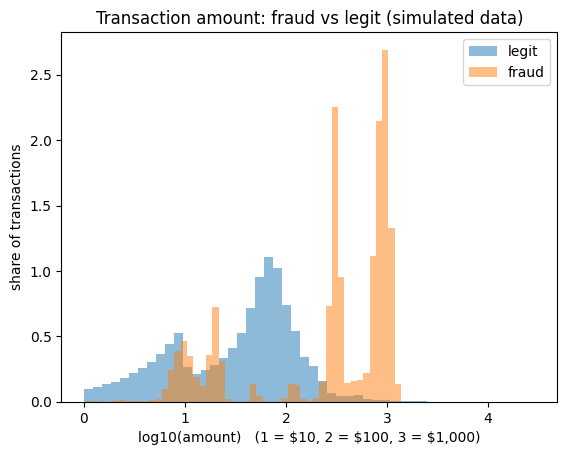

In [84]:
import matplotlib.pyplot as plt, numpy as np

d = duckdb.sql("SELECT amt, is_fraud FROM tx").df()
for label, g in d.groupby('is_fraud'):
    plt.hist(np.log10(g['amt']), bins=50, alpha=0.5, density=True,
             label='fraud' if label else 'legit')
plt.xlabel('log10(amount)   (1 = $10, 2 = $100, 3 = $1,000)')
plt.ylabel('share of transactions')
plt.title('Transaction amount: fraud vs legit (simulated data)')
plt.legend()
plt.savefig('../outputs/amt_fraud_vs_legit.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Time-based split and features

In [85]:
duckdb.sql("""
SELECT CASE WHEN ts < TIMESTAMP '2020-04-21' THEN 'fit' ELSE 'valid' END AS part,
       COUNT(*)                        AS n_tx,
       SUM(is_fraud)                   AS n_fraud,
       ROUND(100.0 * AVG(is_fraud), 3) AS fraud_rate_pct,
       MIN(ts)                         AS first_tx,
       MAX(ts)                         AS last_tx
FROM tx
GROUP BY part
ORDER BY part
""").df()

,part,n_tx,n_fraud,fraud_rate_pct,first_tx,last_tx
0,fit,1142581,6548.0,0.573,2019-01-01 00:00:18,2020-04-20 23:59:50
1,valid,154094,958.0,0.622,2020-04-21 00:00:15,2020-06-21 12:13:37


In [86]:
duckdb.sql("""
CREATE OR REPLACE VIEW feats AS
SELECT
    ts, cc_num, amt, is_fraud,
    CASE WHEN ts < TIMESTAMP '2020-04-21' THEN 'fit' ELSE 'valid' END AS part,
    hr, isodow(ts) AS dow_num, age, LN(amt) AS log_amt, category, city_pop,
    2 * 6371 * asin(sqrt(
        pow(sin(radians(merch_lat - lat) / 2), 2) +
        cos(radians(lat)) * cos(radians(merch_lat)) *
        pow(sin(radians(merch_long - "long") / 2), 2)
    )) AS dist_km
FROM tx
""")

CountBIGINT


In [87]:
duckdb.sql("""
SELECT part, is_fraud, COUNT(*) AS n,
       ROUND(AVG(dist_km), 1)     AS avg_km,
       ROUND(MAX(dist_km), 0)     AS max_km,
       ROUND(AVG(log_amt), 2)     AS avg_log_amt,
       SUM((dist_km IS NULL)::INT) AS null_dist
FROM feats
GROUP BY part, is_fraud
ORDER BY part, is_fraud
""").df()

,part,is_fraud,n,avg_km,max_km,avg_log_amt,null_dist
0,fit,0,1136033,76.1,152.0,3.45,0.0
1,fit,1,6548,76.3,145.0,5.55,0.0
2,valid,0,153136,76.2,148.0,3.44,0.0
3,valid,1,958,76.4,144.0,5.58,0.0


In [88]:
duckdb.sql("""
CREATE OR REPLACE VIEW feats2 AS
SELECT *,
    AVG(amt) OVER w_past                         AS prev_avg_amt,
    amt / AVG(amt) OVER w_past                   AS amt_ratio,
    date_diff('second', LAG(ts) OVER w_ord, ts)  AS secs_since_last,
    COUNT(*) OVER w_24h                          AS tx_prev_24h
FROM feats
WINDOW w_ord  AS (PARTITION BY cc_num ORDER BY ts),
       w_past AS (PARTITION BY cc_num ORDER BY ts
                  ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING),
       w_24h  AS (PARTITION BY cc_num ORDER BY ts
                  RANGE BETWEEN INTERVAL 24 HOURS PRECEDING AND INTERVAL 1 SECOND PRECEDING)
""")

CountBIGINT


In [89]:
duckdb.sql("""
SELECT is_fraud,
       COUNT(*)                                  AS n,
       ROUND(MEDIAN(amt_ratio), 2)               AS med_amt_ratio,
       ROUND(MEDIAN(secs_since_last) / 3600, 1)  AS med_hrs_since_last,
       ROUND(AVG(tx_prev_24h), 2)                AS avg_tx_prev_24h,
       SUM((prev_avg_amt IS NULL)::INT)          AS no_history_rows
FROM feats2
WHERE part = 'fit'
GROUP BY is_fraud
ORDER BY is_fraud
""").df()

,is_fraud,n,med_amt_ratio,med_hrs_since_last,avg_tx_prev_24h,no_history_rows
0,0,1136033,0.66,4.6,3.89,908.0
1,1,6548,5.19,1.3,4.25,63.0


In [90]:
duckdb.sql("SELECT COUNT(DISTINCT cc_num) AS cards_in_fit FROM feats2 WHERE part = 'fit'").df()

,cards_in_fit
0,971


## 4. Models and imbalance comparison

In [91]:
import pandas as pd, numpy as np

cols = ['part','is_fraud','hr','dow_num','age','log_amt','category','city_pop',
        'dist_km','amt_ratio','secs_since_last','tx_prev_24h']
df = duckdb.sql(f"SELECT {', '.join(cols)} FROM feats2 ORDER BY ts").df()

# first transaction on a card has no history: fill with neutral values (no flag)
df['amt_ratio'] = df['amt_ratio'].fillna(1.0)
df['secs_since_last'] = df['secs_since_last'].fillna(df.loc[df.part == 'fit', 'secs_since_last'].median())

# these are heavily skewed, so use logs
df['log_amt_ratio'] = np.log(df['amt_ratio'])
df['log_secs_since_last'] = np.log1p(df['secs_since_last'])
df.shape

(1296675, 14)

In [92]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_score, recall_score

num = ['age','log_amt','city_pop','dist_km','log_amt_ratio','log_secs_since_last','tx_prev_24h']
cat = ['category','hr','dow_num']   # hour is a circle (23 sits next to 0), so treat it as categories

fit, valid = df[df.part == 'fit'], df[df.part == 'valid']
X_fit, y_fit = fit[num + cat], fit['is_fraud']
X_val, y_val = valid[num + cat], valid['is_fraud']

pre = ColumnTransformer([('num', StandardScaler(), num),
                         ('cat', OneHotEncoder(handle_unknown='ignore'), cat)])
lr = Pipeline([('pre', pre),
               ('clf', LogisticRegression(class_weight='balanced', max_iter=1000))])
lr.fit(X_fit, y_fit)

p = lr.predict_proba(X_val)[:, 1]
pred = p >= 0.5
print('valid fraud rate (a random guess scores about this PR-AUC):', round(y_val.mean(), 4))
print('LR + class weights   PR-AUC:', round(average_precision_score(y_val, p), 3))
print('at threshold 0.5     precision:', round(precision_score(y_val, pred), 3),
      ' recall:', round(recall_score(y_val, pred), 3))

valid fraud rate (a random guess scores about this PR-AUC): 0.0062
LR + class weights   PR-AUC: 0.41
at threshold 0.5     precision: 0.033  recall: 0.843


In [93]:
results = []
def log_result(name, probs):
    results.append({'model': name, 'PR-AUC': round(average_precision_score(y_val, probs), 3)})
    return pd.DataFrame(results)

log_result('LR + class weights', p)

lr_none = Pipeline([('pre', pre),
                    ('clf', LogisticRegression(max_iter=1000))])
lr_none.fit(X_fit, y_fit)
log_result('LR + no weighting', lr_none.predict_proba(X_val)[:, 1])

,model,PR-AUC
0,LR + class weights,0.410
1,LR + no weighting,0.508


In [94]:
%%time
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OrdinalEncoder

feat_t = ['hr','dow_num','age','log_amt','city_pop','dist_km',
          'log_amt_ratio','log_secs_since_last','tx_prev_24h','category']
pre_t = ColumnTransformer(
    [('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), ['category'])],
    remainder='passthrough')

rf = Pipeline([('pre', pre_t),
               ('clf', RandomForestClassifier(n_estimators=100, max_depth=12,
                                              min_samples_leaf=20, max_samples=0.3,
                                              class_weight='balanced_subsample',
                                              n_jobs=-1, random_state=42))])
rf.fit(fit[feat_t], y_fit)
p_rf = rf.predict_proba(valid[feat_t])[:, 1]
log_result('RF + class weights', p_rf)

CPU times: user 1min 13s, sys: 576 ms, total: 1min 14s
Wall time: 8.9 s


,model,PR-AUC
0,LR + class weights,0.410
1,LR + no weighting,0.508
2,RF + class weights,0.873


In [95]:
try:
    import xgboost
    print('xgboost OK, version', xgboost.__version__)
except Exception as e:
    print(type(e).__name__, '-', str(e)[:500])

xgboost OK, version 3.4.1


In [96]:
%%time
from xgboost import XGBClassifier

spw = (y_fit == 0).sum() / (y_fit == 1).sum()      # about 173

def make_xgb(scale_pos_weight):
    return Pipeline([('pre', pre_t),
                     ('clf', XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                                           subsample=0.8, colsample_bytree=0.8,
                                           tree_method='hist', n_jobs=-1, random_state=42,
                                           scale_pos_weight=scale_pos_weight))])

xgb_none = make_xgb(1).fit(fit[feat_t], y_fit)
log_result('XGB + no weighting', xgb_none.predict_proba(valid[feat_t])[:, 1])

xgb_w = make_xgb(spw).fit(fit[feat_t], y_fit)
p_xgb_w = xgb_w.predict_proba(valid[feat_t])[:, 1]
log_result('XGB + class weights', p_xgb_w)

CPU times: user 31.4 s, sys: 1.54 s, total: 33 s
Wall time: 7 s


,model,PR-AUC
0,LR + class weights,0.410
1,LR + no weighting,0.508
2,RF + class weights,0.873
3,XGB + no weighting,0.949
4,XGB + class weights,0.943


In [97]:
%%time
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, SMOTENC

xgb_smote = ImbPipeline([
    ('pre', pre_t),                                    # category becomes column 0
    ('smote', SMOTENC(categorical_features=[0], sampling_strategy=0.1, random_state=42)),
    ('clf', XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8,
                          colsample_bytree=0.8, tree_method='hist', n_jobs=-1, random_state=42))])
xgb_smote.fit(fit[feat_t], y_fit)
log_result('XGB + SMOTE', xgb_smote.predict_proba(valid[feat_t])[:, 1])

CPU times: user 19.2 s, sys: 1e+03 ms, total: 20.2 s
Wall time: 7.18 s


,model,PR-AUC
0,LR + class weights,0.410
1,LR + no weighting,0.508
2,RF + class weights,0.873
3,XGB + no weighting,0.949
4,XGB + class weights,0.943
5,XGB + SMOTE,0.926


In [98]:
%%time
lr_smote = ImbPipeline([('pre', pre),
                        ('smote', SMOTE(sampling_strategy=0.1, random_state=42)),
                        ('clf', LogisticRegression(max_iter=1000))])
lr_smote.fit(X_fit, y_fit)
log_result('LR + SMOTE', lr_smote.predict_proba(X_val)[:, 1])

CPU times: user 1.69 s, sys: 87.6 ms, total: 1.77 s
Wall time: 1.78 s


,model,PR-AUC
0,LR + class weights,0.410
1,LR + no weighting,0.508
2,RF + class weights,0.873
3,XGB + no weighting,0.949
4,XGB + class weights,0.943
5,XGB + SMOTE,0.926
6,LR + SMOTE,0.464


## 5. Threshold chosen by dollar cost

In [99]:
R = 5                                              # review cost per alert ($), state in README
p_xgb = xgb_none.predict_proba(valid[feat_t])[:, 1]
y = y_val.values
amt = np.exp(valid['log_amt'].values).round(2)     # back to dollars

rows = []
for t in [0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    flag = p_xgb >= t
    caught = flag & (y == 1)
    missed = (~flag) & (y == 1)
    rows.append({'threshold': t,
                 'alerts': int(flag.sum()),
                 'recall': round(caught.sum() / y.sum(), 3),
                 'precision': round(caught.sum() / max(flag.sum(), 1), 3),
                 'fraud_$_caught': round(amt[caught].sum()),
                 'fraud_$_missed': round(amt[missed].sum()),
                 'review_cost_$': R * int(flag.sum())})
sweep = pd.DataFrame(rows)
sweep['net_savings_$'] = sweep['fraud_$_caught'] - sweep['review_cost_$']
print(sweep.to_string(index=False))
print()
print(sweep.loc[sweep['net_savings_$'].idxmax()])

 threshold  alerts  recall  precision  fraud_$_caught  fraud_$_missed  review_cost_$  net_savings_$
      0.02    1776   0.965      0.520          509601            4496           8880         500721
      0.05    1355   0.948      0.670          506590            7507           6775         499815
      0.10    1150   0.929      0.774          502997           11100           5750         497247
      0.20     995   0.895      0.861          493635           20462           4975         488660
      0.30     930   0.876      0.902          486857           27240           4650         482207
      0.40     871   0.847      0.931          471386           42712           4355         467031
      0.50     842   0.831      0.945          461324           52773           4210         457114
      0.60     802   0.803      0.959          447859           66238           4010         443849
      0.70     770   0.784      0.975          437416           76681           3850         433566


In [100]:
def sweep_t(ths):
    rows = []
    for t in ths:
        flag = p_xgb >= t
        caught = flag & (y == 1)
        rows.append({'threshold': t, 'alerts': int(flag.sum()),
                     'recall': round(caught.sum() / y.sum(), 3),
                     'precision': round(caught.sum() / max(flag.sum(), 1), 3),
                     'fraud_$_caught': round(amt[caught].sum()),
                     'fraud_$_missed': round(amt[(~flag) & (y == 1)].sum()),
                     'review_cost_$': R * int(flag.sum())})
    out = pd.DataFrame(rows)
    out['net_savings_$'] = out['fraud_$_caught'] - out['review_cost_$']
    return out

s2 = sweep_t([0.001, 0.003, 0.005, 0.0075, 0.01, 0.015, 0.02, 0.03])
print(s2.to_string(index=False))
print()
print(s2.loc[s2['net_savings_$'].idxmax()])

 threshold  alerts  recall  precision  fraud_$_caught  fraud_$_missed  review_cost_$  net_savings_$
    0.0010    7133   0.999      0.134          513462             635          35665         477797
    0.0030    4033   0.995      0.236          513306             791          20165         493141
    0.0050    3195   0.987      0.296          512370            1727          15975         496395
    0.0075    2645   0.982      0.356          512283            1814          13225         499058
    0.0100    2337   0.975      0.400          511816            2281          11685         500131
    0.0150    1981   0.971      0.469          511746            2351           9905         501841
    0.0200    1776   0.965      0.520          509601            4496           8880         500721
    0.0300    1561   0.957      0.587          507487            6610           7805         499682

threshold              0.015
alerts              1981.000
recall                 0.971
precision   

category               0.425
log_amt                0.322
log_secs_since_last    0.081
hr                     0.077
tx_prev_24h            0.026
log_amt_ratio          0.026
age                    0.021
city_pop               0.010
dow_num                0.008
dist_km                0.006
dtype: float32


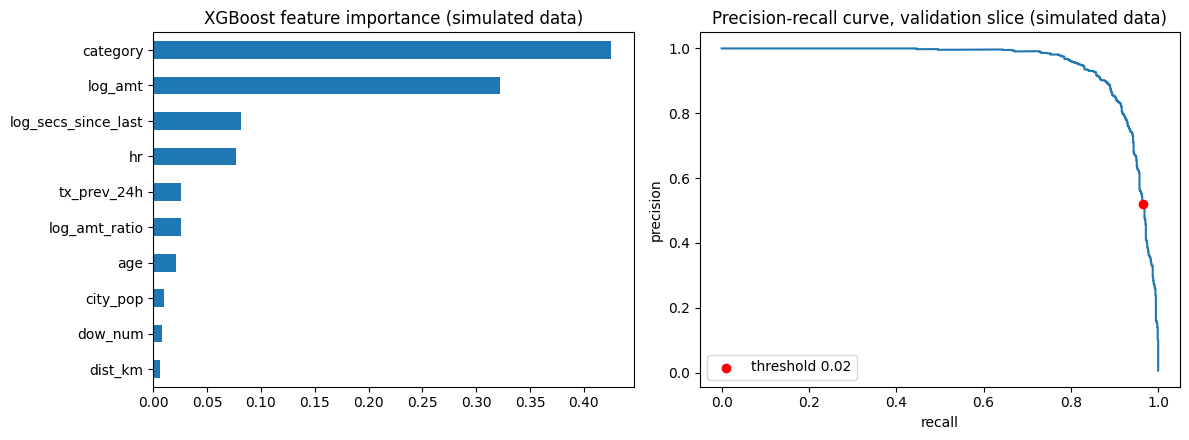

In [101]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

THRESHOLD = 0.02      # frozen: chosen on the validation slice by net savings

# feature importance (names follow the pipeline's column order: category first)
names = ['category'] + [c for c in feat_t if c != 'category']
imp = pd.Series(xgb_none.named_steps['clf'].feature_importances_, index=names).sort_values()
print(imp.sort_values(ascending=False).round(3).head(10))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
imp.tail(10).plot.barh(ax=ax[0])
ax[0].set_title('XGBoost feature importance (simulated data)')

prec, rec, _ = precision_recall_curve(y, p_xgb)
ax[1].plot(rec, prec)
chosen = p_xgb >= THRESHOLD
ax[1].scatter([(chosen & (y == 1)).sum() / y.sum()], [(chosen & (y == 1)).sum() / chosen.sum()],
              color='red', zorder=3, label=f'threshold {THRESHOLD}')
ax[1].set_xlabel('recall'); ax[1].set_ylabel('precision')
ax[1].set_title('Precision-recall curve, validation slice (simulated data)')
ax[1].legend()
plt.tight_layout()
plt.savefig('../outputs/importance_and_pr_curve.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Final test evaluation

In [102]:
duckdb.sql("""
CREATE OR REPLACE VIEW all_tx AS
SELECT *, 'train' AS src FROM read_csv_auto('../data/fraudTrain.csv')
UNION ALL
SELECT *, 'test'  AS src FROM read_csv_auto('../data/fraudTest.csv')
""")

duckdb.sql("""
CREATE OR REPLACE VIEW feats_all AS
WITH base AS (
    SELECT src, cc_num, is_fraud, amt, category, city_pop, lat, "long", merch_lat, merch_long,
           CAST(trans_date_trans_time AS TIMESTAMP) AS ts,
           CAST(dob AS DATE) AS dob_d
    FROM all_tx
)
SELECT src, ts, cc_num, amt, is_fraud, category, city_pop,
       hour(ts) AS hr, isodow(ts) AS dow_num,
       date_diff('year', dob_d, CAST(ts AS DATE)) AS age,
       LN(amt) AS log_amt,
       2 * 6371 * asin(sqrt(
           pow(sin(radians(merch_lat - lat) / 2), 2) +
           cos(radians(lat)) * cos(radians(merch_lat)) *
           pow(sin(radians(merch_long - "long") / 2), 2))) AS dist_km,
       amt / AVG(amt) OVER w_past                  AS amt_ratio,
       date_diff('second', LAG(ts) OVER w_ord, ts) AS secs_since_last,
       COUNT(*) OVER w_24h                         AS tx_prev_24h
FROM base
WINDOW w_ord  AS (PARTITION BY cc_num ORDER BY ts),
       w_past AS (PARTITION BY cc_num ORDER BY ts
                  ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING),
       w_24h  AS (PARTITION BY cc_num ORDER BY ts
                  RANGE BETWEEN INTERVAL 24 HOURS PRECEDING AND INTERVAL 1 SECOND PRECEDING)
""")

CountBIGINT


In [103]:
# 1) adding test must not change any train feature (past-only features can't see the future)
print(duckdb.sql("""
SELECT 'feats2 (train only)' AS source, COUNT(*) AS n, ROUND(SUM(amt_ratio), 2) AS sum_amt_ratio,
       SUM(tx_prev_24h) AS sum_tx24, SUM(secs_since_last) AS sum_secs
FROM feats2
UNION ALL
SELECT 'feats_all (train rows)', COUNT(*), ROUND(SUM(amt_ratio), 2), SUM(tx_prev_24h), SUM(secs_since_last)
FROM feats_all WHERE src = 'train'
""").df().to_string(index=False))

# 2) test file size and dates only
print(duckdb.sql("""
SELECT src, COUNT(*) AS n_tx, MIN(ts) AS first_tx, MAX(ts) AS last_tx, COUNT(DISTINCT cc_num) AS n_cards
FROM feats_all GROUP BY src ORDER BY src
""").df().to_string(index=False))

                source       n  sum_amt_ratio  sum_tx24     sum_secs
   feats2 (train only) 1296675     1323052.46 5036479.0 4.209057e+10
feats_all (train rows) 1296675     1323052.46 5036479.0 4.209057e+10
  src    n_tx            first_tx             last_tx  n_cards
 test  555719 2020-06-21 12:14:25 2020-12-31 23:59:34      924
train 1296675 2019-01-01 00:00:18 2020-06-21 12:13:37      983


In [104]:
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix)

fill_secs = duckdb.sql("SELECT MEDIAN(secs_since_last) FROM feats2 WHERE part = 'fit'").df().iloc[0, 0]

te = duckdb.sql("""SELECT ts, amt, is_fraud, hr, dow_num, age, log_amt, category, city_pop,
                          dist_km, amt_ratio, secs_since_last, tx_prev_24h
                   FROM feats_all WHERE src = 'test' ORDER BY ts""").df()
print('test rows with no card history:', int(te['amt_ratio'].isna().sum()))

te['amt_ratio'] = te['amt_ratio'].fillna(1.0)
te['secs_since_last'] = te['secs_since_last'].fillna(fill_secs)
te['log_amt_ratio'] = np.log(te['amt_ratio'])
te['log_secs_since_last'] = np.log1p(te['secs_since_last'])

THRESHOLD, R = 0.02, 5                      # frozen on validation
p_te = xgb_none.predict_proba(te[feat_t])[:, 1]
y_te = te['is_fraud'].values
flag = p_te >= THRESHOLD
caught = flag & (y_te == 1)
missed = ~flag & (y_te == 1)
amt_te = te['amt'].values

tn, fp, fn, tp = confusion_matrix(y_te, flag).ravel()
summary = {
    'n_tx': len(te), 'n_fraud': int(y_te.sum()), 'fraud_rate_pct': round(100 * y_te.mean(), 3),
    'PR_AUC': round(average_precision_score(y_te, p_te), 3),
    'threshold': THRESHOLD, 'alerts': int(flag.sum()),
    'precision': round(precision_score(y_te, flag), 3),
    'recall': round(recall_score(y_te, flag), 3),
    'F1': round(f1_score(y_te, flag), 3),
    'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
    'fraud_$_total': round(amt_te[y_te == 1].sum()),
    'fraud_$_caught': round(amt_te[caught].sum()),
    'fraud_$_missed': round(amt_te[missed].sum()),
    'review_cost_$': R * int(flag.sum()),
}
summary['net_savings_$'] = summary['fraud_$_caught'] - summary['review_cost_$']
summary['pct_fraud_$_caught'] = round(100 * summary['fraud_$_caught'] / summary['fraud_$_total'], 1)

s = pd.Series(summary)
print(s.to_string())
s.to_csv('../outputs/final_test_summary.csv', header=['value'])

test rows with no card history: 16
n_tx                   555719.000
n_fraud                  2145.000
fraud_rate_pct              0.386
PR_AUC                      0.907
threshold                   0.020
alerts                   4999.000
precision                   0.405
recall                      0.944
F1                          0.567
TN                     550599.000
FP                       2975.000
FN                        121.000
TP                       2024.000
fraud_$_total         1133325.000
fraud_$_caught        1114753.000
fraud_$_missed          18571.000
review_cost_$           24995.000
net_savings_$         1089758.000
pct_fraud_$_caught         98.400


## 7. Exports for Tableau and Excel

In [105]:
te['flag'] = flag
te['caught'] = caught
te['fraud_amt'] = te['amt'] * te['is_fraud']
te['caught_amt'] = te['amt'] * te['caught'].astype(int)
te['month'] = te['ts'].dt.to_period('M').astype(str)

def seg(col):
    out = te.groupby(col).agg(n_tx=('amt', 'size'), n_fraud=('is_fraud', 'sum'),
                              alerts=('flag', 'sum'), fraud_caught=('caught', 'sum'),
                              fraud_usd=('fraud_amt', 'sum'),
                              fraud_usd_caught=('caught_amt', 'sum')).reset_index()
    out['fraud_rate'] = out['n_fraud'] / out['n_tx']
    return out

for col in ['category', 'hr', 'month']:
    seg(col).to_csv(f'../outputs/test_by_{col}.csv', index=False)

seg('month')

,month,n_tx,n_fraud,alerts,fraud_caught,fraud_usd,fraud_usd_caught,fraud_rate
0,2020-06,30058,133,295,125,73274.93,72581.51,0.004425
1,2020-07,85848,321,755,301,158669.49,156321.96,0.003739
2,2020-08,88759,415,866,385,208785.43,203042.54,0.004676
3,2020-09,69533,340,703,325,202700.99,198857.23,0.004890
4,2020-10,69348,384,746,355,195572.97,191793.65,0.005537
5,2020-11,72635,294,671,286,153182.19,151879.73,0.004048
6,2020-12,139538,258,963,247,141138.68,140276.75,0.001849


## 8. Checks behind the dashboard takeaway

In [106]:
cat = pd.read_csv('../outputs/test_by_category.csv')
hr = pd.read_csv('../outputs/test_by_hr.csv')
print(cat.assign(fraud_rate=(cat.fraud_rate * 100).round(3)).sort_values('fraud_rate', ascending=False).to_string(index=False))
print()
print(hr.assign(fraud_rate=(hr.fraud_rate * 100).round(3)).to_string(index=False))

      category  n_tx  n_fraud  alerts  fraud_caught  fraud_usd  fraud_usd_caught  fraud_rate
  shopping_net 41779      506     910           503  503123.93         500206.84       1.211
      misc_net 27367      267     465           263  214742.95         211804.64       0.976
   grocery_pos 52553      485     516           484  151866.72         151625.27       0.923
  shopping_pos 49791      213     499           206  188887.25         182539.85       0.428
 gas_transport 56370      154     193           154    1848.42           1848.42       0.273
        travel 17449       40     167            20     347.98            189.93       0.229
   grocery_net 19426       41     238            41     478.39            478.39       0.211
      misc_pos 34574       72     385            59   13923.82          13154.56       0.208
 personal_care 39327       70     375            54    1814.44           1315.34       0.178
 entertainment 40104       59     126            59   30076.17        

In [107]:
night = hr[hr.hr.isin([22, 23, 0, 1, 2, 3])]
print('night share of tx:', round(night.n_tx.sum() / hr.n_tx.sum() * 100, 1),
      '| of fraud cases:', round(night.n_fraud.sum() / hr.n_fraud.sum() * 100, 1),
      '| of fraud $:', round(night.fraud_usd.sum() / hr.fraud_usd.sum() * 100, 1))
top3 = cat[cat.category.isin(['shopping_net', 'misc_net', 'grocery_pos'])]
print('top-3 categories share of fraud $:', round(top3.fraud_usd.sum() / cat.fraud_usd.sum() * 100, 1),
      '| shopping_net alone:', round(cat.loc[cat.category == 'shopping_net', 'fraud_usd'].iloc[0] / cat.fraud_usd.sum() * 100, 1))

night share of tx: 23.4 | of fraud cases: 84.2 | of fraud $: 84.7
top-3 categories share of fraud $: 76.7 | shopping_net alone: 44.4
